In [34]:
import pandas as pd                  # Data manipulation and preprocessing
import matplotlib.pyplot as plt      # Data visualization and plotting
import seaborn as sns    

In [35]:
# Load the data
path = r"files\WMDI-files\house_price_prediction_dataset.csv"

df = pd.read_csv(path)

In [36]:
df.head()

,PropertyID,Location,PropertyType,SizeInSqFt,Bedrooms,Bathrooms,YearBuilt,GarageSpaces,LotSize,NearbySchools,MarketTrend,SellingPrice
0,1,Downtown,Condo,1217.0,2.0,1.0,1959,0,2273.0,4,1,391780.0
1,2,Beachfront,Single Family,2385.0,5.0,3.0,2006,1,1631.0,5,1,1195998.0
2,3,Suburbs,Single Family,2405.0,6.0,3.0,1986,3,3800.0,1,1,736928.0
3,4,Suburbs,Single Family,1790.0,2.0,2.0,2013,1,4347.0,7,1,528240.0
4,5,Downtown,Single Family,2563.0,5.0,2.0,1989,3,3320.0,7,1,958097.0


In [37]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   PropertyID     1500 non-null   int64  
 1   Location       1500 non-null   str    
 2   PropertyType   1500 non-null   str    
 3   SizeInSqFt     1425 non-null   float64
 4   Bedrooms       1425 non-null   float64
 5   Bathrooms      1425 non-null   float64
 6   YearBuilt      1500 non-null   int64  
 7   GarageSpaces   1500 non-null   int64  
 8   LotSize        1425 non-null   float64
 9   NearbySchools  1500 non-null   int64  
 10  MarketTrend    1500 non-null   int64  
 11  SellingPrice   1500 non-null   float64
dtypes: float64(5), int64(5), str(2)
memory usage: 140.8 KB


In [38]:
df.describe()

,PropertyID,SizeInSqFt,Bedrooms,Bathrooms,YearBuilt,GarageSpaces,LotSize,NearbySchools,MarketTrend,SellingPrice
count,1500.000000,1425.000000,1425.000000,1425.000000,1500.00000,1500.000000,1425.000000,1500.000000,1500.000000,1.500000e+03
mean,750.500000,1610.717895,3.082807,1.687719,1985.91800,1.085333,4127.230175,5.695333,-0.003333,5.112892e+05
std,433.157015,664.183550,1.675633,0.782550,20.88149,0.929495,2314.593053,2.288377,0.759632,2.393133e+05
min,1.000000,500.000000,1.000000,1.000000,1950.00000,0.000000,1000.000000,1.000000,-1.000000,1.217560e+05
25%,375.750000,995.000000,1.000000,1.000000,1968.00000,0.000000,2181.000000,4.000000,-1.000000,3.075755e+05
50%,750.500000,1639.000000,3.000000,2.000000,1986.00000,1.000000,3949.000000,6.000000,0.000000,4.583810e+05
75%,1125.250000,2199.000000,4.000000,2.000000,2004.00000,2.000000,5603.000000,7.000000,1.000000,7.017140e+05
max,1500.000000,3060.000000,6.000000,4.000000,2022.00000,3.000000,10458.000000,10.000000,1.000000,1.416213e+06


In [39]:
# Remove irrelevant features
df.drop("PropertyID", axis=1, inplace=True)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_23168\724474426.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop("PropertyID", axis=1, inplace=True)


### Handle missing values

In [40]:
df.isnull().mean()*100 # percentage of missing values


Location         0.0
PropertyType     0.0
SizeInSqFt       5.0
Bedrooms         5.0
Bathrooms        5.0
YearBuilt        0.0
GarageSpaces     0.0
LotSize          5.0
NearbySchools    0.0
MarketTrend      0.0
SellingPrice     0.0
dtype: float64

In [41]:
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Location       1500 non-null   str    
 1   PropertyType   1500 non-null   str    
 2   SizeInSqFt     1425 non-null   float64
 3   Bedrooms       1425 non-null   float64
 4   Bathrooms      1425 non-null   float64
 5   YearBuilt      1500 non-null   int64  
 6   GarageSpaces   1500 non-null   int64  
 7   LotSize        1425 non-null   float64
 8   NearbySchools  1500 non-null   int64  
 9   MarketTrend    1500 non-null   int64  
 10  SellingPrice   1500 non-null   float64
dtypes: float64(5), int64(4), str(2)
memory usage: 129.0 KB


In [42]:
# Fill missing numerical values with each column's median
df["SizeInSqFt"] = df["SizeInSqFt"].fillna(df["SizeInSqFt"].median())
df["Bedrooms"] = df["Bedrooms"].fillna(df["Bedrooms"].median())
df["Bathrooms"] = df["Bathrooms"].fillna(df["Bathrooms"].median())
df["LotSize"] = df["LotSize"].fillna(df["LotSize"].median())

In [43]:
df.isnull().mean()*100 # confirm missing values are gone

Location         0.0
PropertyType     0.0
SizeInSqFt       0.0
Bedrooms         0.0
Bathrooms        0.0
YearBuilt        0.0
GarageSpaces     0.0
LotSize          0.0
NearbySchools    0.0
MarketTrend      0.0
SellingPrice     0.0
dtype: float64

### Encode Categorical Data (Convert them to Numeric Binary)

In [44]:
from sklearn.preprocessing import LabelEncoder

In [45]:
df.head() # Location and PropertyType to be encoded

,Location,PropertyType,SizeInSqFt,Bedrooms,Bathrooms,YearBuilt,GarageSpaces,LotSize,NearbySchools,MarketTrend,SellingPrice
0,Downtown,Condo,1217.0,2.0,1.0,1959,0,2273.0,4,1,391780.0
1,Beachfront,Single Family,2385.0,5.0,3.0,2006,1,1631.0,5,1,1195998.0
2,Suburbs,Single Family,2405.0,6.0,3.0,1986,3,3800.0,1,1,736928.0
3,Suburbs,Single Family,1790.0,2.0,2.0,2013,1,4347.0,7,1,528240.0
4,Downtown,Single Family,2563.0,5.0,2.0,1989,3,3320.0,7,1,958097.0


In [46]:
encoder = LabelEncoder()

In [47]:
df["Location"] = encoder.fit_transform(df["Location"])
df["PropertyType"] = encoder.fit_transform(df["PropertyType"])

In [48]:
df.head() # confirm if encoded

,Location,PropertyType,SizeInSqFt,Bedrooms,Bathrooms,YearBuilt,GarageSpaces,LotSize,NearbySchools,MarketTrend,SellingPrice
0,2,0,1217.0,2.0,1.0,1959,0,2273.0,4,1,391780.0
1,0,1,2385.0,5.0,3.0,2006,1,1631.0,5,1,1195998.0
2,3,1,2405.0,6.0,3.0,1986,3,3800.0,1,1,736928.0
3,3,1,1790.0,2.0,2.0,2013,1,4347.0,7,1,528240.0
4,2,1,2563.0,5.0,2.0,1989,3,3320.0,7,1,958097.0


### Scale The Features (mean=0, std=1)

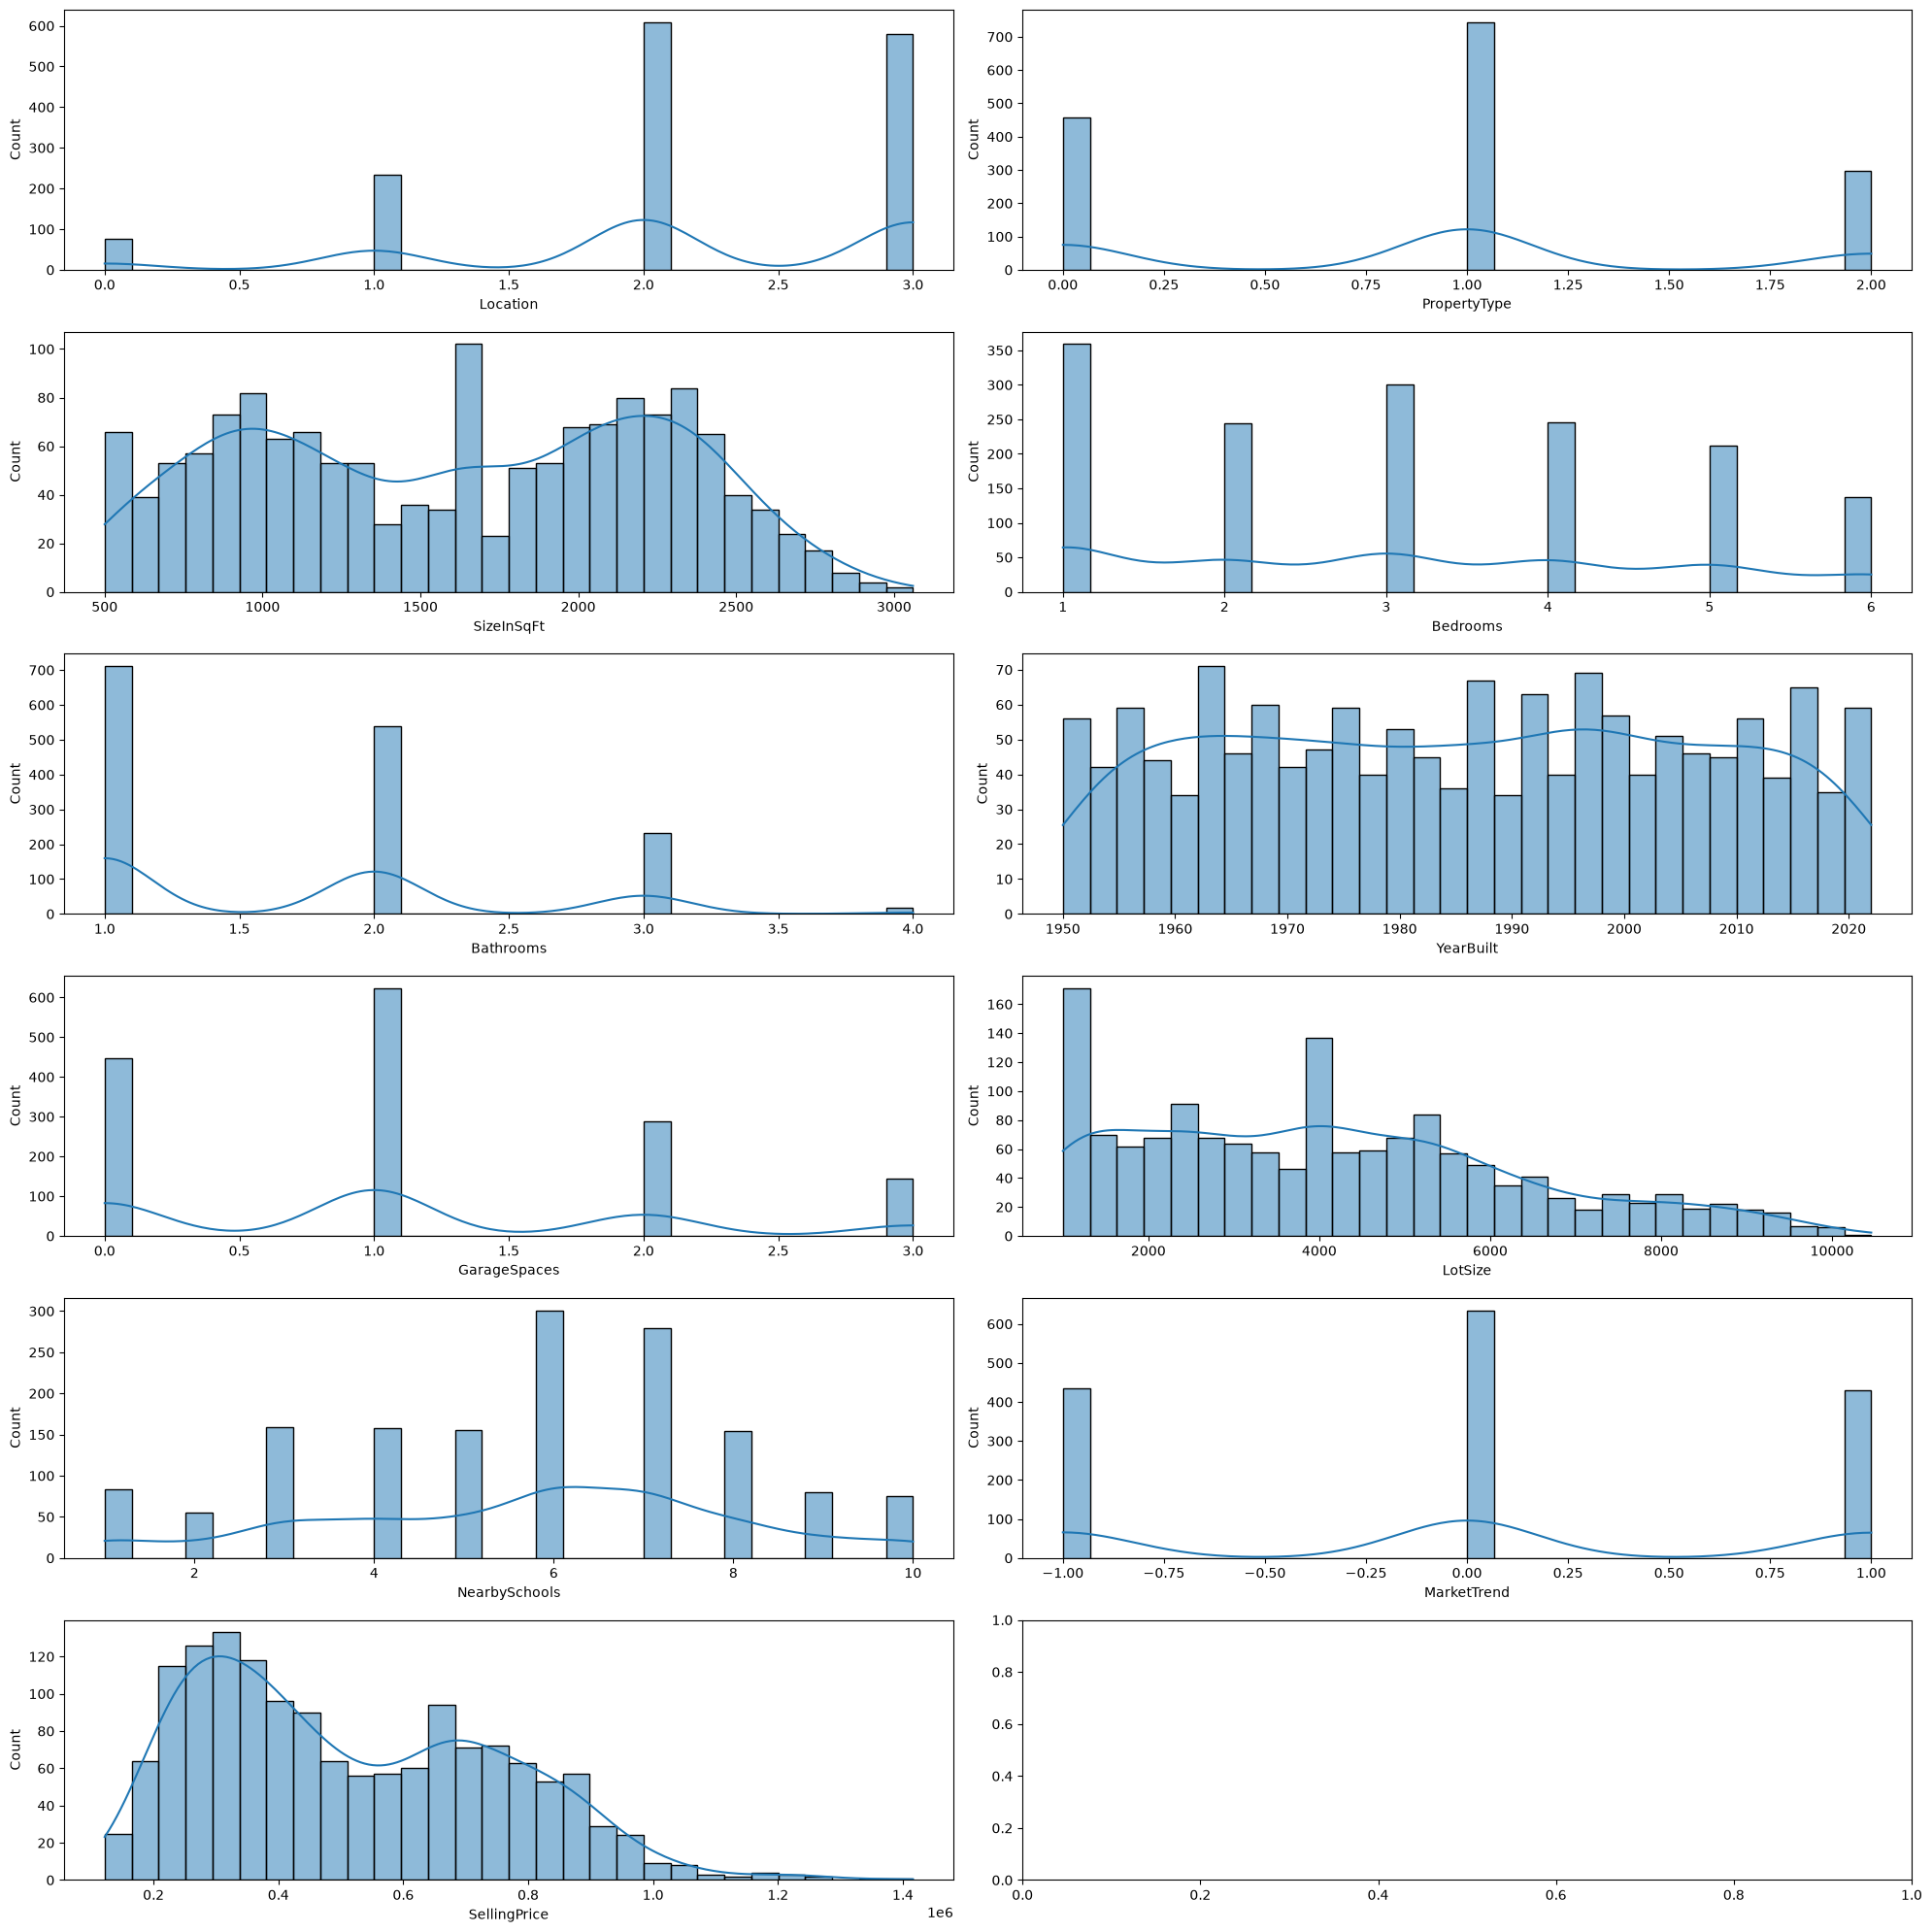

In [49]:
fig, ax = plt.subplots(6, 2, figsize=(20,20))
ax = ax.flatten()

for idx, col in enumerate(df):
    sns.histplot(df[col], kde=True, bins=30, ax=ax[idx])

plt.tight_layout()
plt.show()

In [50]:
from sklearn.preprocessing import MinMaxScaler # Normally distributed or slightly skewed standardScaler, heavily skewed RobustScaler

In [51]:
scaler = MinMaxScaler()

In [52]:
cols_to_scale = ["SizeInSqFt", "YearBuilt", "LotSize"] # categorical columns shouldnt be scaled
df[cols_to_scale] = scaler.fit_transform(df[cols_to_scale])

In [53]:
df.head()

,Location,PropertyType,SizeInSqFt,Bedrooms,Bathrooms,YearBuilt,GarageSpaces,LotSize,NearbySchools,MarketTrend,SellingPrice
0,2,0,0.280078,2.0,1.0,0.125000,0,0.134595,4,1,391780.0
1,0,1,0.736328,5.0,3.0,0.777778,1,0.066716,5,1,1195998.0
2,3,1,0.744141,6.0,3.0,0.500000,3,0.296046,1,1,736928.0
3,3,1,0.503906,2.0,2.0,0.875000,1,0.353880,7,1,528240.0
4,2,1,0.805859,5.0,2.0,0.541667,3,0.245295,7,1,958097.0


### Define the Features and Target Variables

In [54]:
X =  df.drop("SellingPrice", axis=1)
y = df["SellingPrice"]

### Data Splitting

In [55]:
from sklearn.model_selection import train_test_split 

In [56]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

### Modelling

In [57]:
from sklearn.linear_model import LinearRegression

In [58]:
model =  LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ -14601.62, 21643.42, 548093.23,...,-401928.69, 5496.55, 11909.85]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](10,)","['Location','PropertyType','SizeInSqFt',...,'LotSize','NearbySchools', 'MarketTrend']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.2e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(10)


### Coefficient and Itercepts

##### Coeficient tells us how each column contribute to the selling price
##### Intercept tells the seling price if every column is set to zero

In [59]:
coef = model.coef_
intercept = model.intercept_
print(f"{coef}")
print(f"{intercept}")

[ -14601.62045072   21643.41507943  548093.22995906   32808.05220895
   21988.4740162    21140.17025878   13524.80167377 -401928.68520769
    5496.5495357    11909.85146471]
220017.95902341505


metrics above can be differnrt from the insights below as insights were written from a different insghts. The logic remains the same

***Result Interpretation:***

- **Intercept (280,311.01):**
    - The intercept represents the predicted base selling price of a property when all features (predictors) are zero.
    - In this case, it serves as the baseline price before accounting for factors like size, location, and amenities.
    - Since having "zero" for features like SizeInSqFt or Bedrooms is unrealistic, the intercept mainly provides a starting value for the model predictions.
 

- **Coefficients:**
Each coefficient represents the change in the predicted selling price for a one-unit increase in the respective feature, holding all other features constant.

***Feature	Coefficient	Interpretation***
| **Feature**       | **Coefficient**   | **Interpretation**                                                                                                                                      |
|-------------------|-------------------|--------------------------------------------------------------------------------------------------------------------------------------------------------|
| **Location**      | -14,601.62        | A one-unit increase in `Location` results in a decrease of \$14,601.62 in the predicted selling price, indicating that certain locations may reduce the price. |
| **PropertyType**  | 21,643.42         | A one-unit increase in `PropertyType` corresponds to an increase of \$21,643.42 in the selling price, suggesting that certain property types (e.g., Single Family) increase the price. |
| **SizeInSqFt**    | 548,093.23        | A one-unit increase in `SizeInSqFt` results in an increase of \$548,093.23 in the predicted price, indicating a strong positive relationship between size and price. |
| **Bedrooms**      | 164,040.26        | A one-bedroom increase results in an increase of \$164,040.26 in price, showing that more bedrooms contribute to a higher property value. |
| **Bathrooms**     | 65,965.42         | Each additional bathroom increases the predicted price by \$65,965.42, suggesting that more bathrooms add value to the property. |
| **YearBuilt**     | 21,140.17         | A one-year increase in `YearBuilt` leads to an increase of \$21,140.17 in price, indicating that newer homes tend to have a higher price. |
| **GarageSpaces**  | 40,574.41         | Each additional garage space increases the price by \$40,574.41, reflecting the value added by more garage spaces. |
| **LotSize**       | -401,928.69       | A one-unit increase in `LotSize` results in a decrease of \$401,928.69 in price, possibly indicating that larger lot sizes in certain areas reduce the property value. |
| **NearbySchools** | 49,468.95         | A one-unit increase in `NearbySchools` leads to an increase of \$49,468.95 in the predicted price, indicating that properties near highly rated schools are valued higher. |
| **MarketTrend**   | 11,909.85         | A one-unit increase in `MarketTrend` corresponds to an increase of \$11,909.85 in price, suggesting that properties in areas with improving market trends are valued higher. |

                       

- **Insights:**
    1. High Impact Features on Property Price:
        - SizeInSqFt and Bedrooms have the highest coefficients, suggesting that the size of the property and the number of bedrooms are crucial factors in determining the property’s selling price. Larger properties with more bedrooms are significantly more valuable.

    2. Positive Correlation with Price:

        - Features such as PropertyType, Bathrooms, YearBuilt, GarageSpaces, NearbySchools, and MarketTrend all show positive coefficients, meaning that increases in these factors generally lead to higher property prices. For example, being closer to good schools or having more bathrooms or garage spaces tends to increase the value of a property.

    3. Negative Impact of Certain Features:

        - Location and LotSize have negative coefficients, meaning that properties in certain locations (perhaps less desirable areas) or with larger lot sizes may have a reduced selling price. Larger lot sizes, for instance, might not always translate to higher value, possibly due to lower demand for large land areas or specific geographic areas.

    4. Significance of Market and Location:

        - MarketTrend and Location both show how external factors influence the price. A better market trend increases property value, while a less desirable location reduces it.

    5. Subtle Influence of YearBuilt:

        - The YearBuilt feature also contributes positively, but with a relatively smaller impact compared to others like size or bedrooms. Newer properties tend to be worth more, but this relationship is not as pronounced as other variables.

In [60]:
y_pred = model.predict(X_test)


Evaluate the model using common regression metrics:
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² Score

In [61]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [62]:
mae = mean_absolute_error(y_test, y_pred)
mse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

In [63]:
print(f"Mean Absolute Error (MAE): {mae}")
print(f"Root Mean Squared Error (RMSE): {mse}")
print(f"R² Score: {r2}")

Mean Absolute Error (MAE): 67620.67440010015
Root Mean Squared Error (RMSE): 90705.0388868256
R² Score: 0.8673454227156007


**1. Mean Absolute Error (MAE): \$67,620.67**
- On average, the model's predictions deviate from the actual house prices by \$67,620.
- This value provides a direct measure of prediction error in dollars, making it easy for stakeholders to understand.
  
**2. Root Mean Squared Error (RMSE): \$90,705.03**
- RMSE penalizes larger errors more than MAE due to squaring differences.
- An RMSE of ~$90,705 suggests the model has some room for improvement, especially for outlier predictions.
    
**3. R² (R-Squared): 0.86**
- The model explains 86% of the variance in house prices based on the given features.
- This is a strong result, indicating that the model captures most of the important factors influencing prices.
- However, 14% of the variance remains unexplained, possibly due to missing features (e.g., economic trends, interest rates) or randomness in the data.

###  Residual Analysis
Analyze residuals to assess the model's performance.

In [64]:
# Plot residuals
residuals = y_test - y_pred


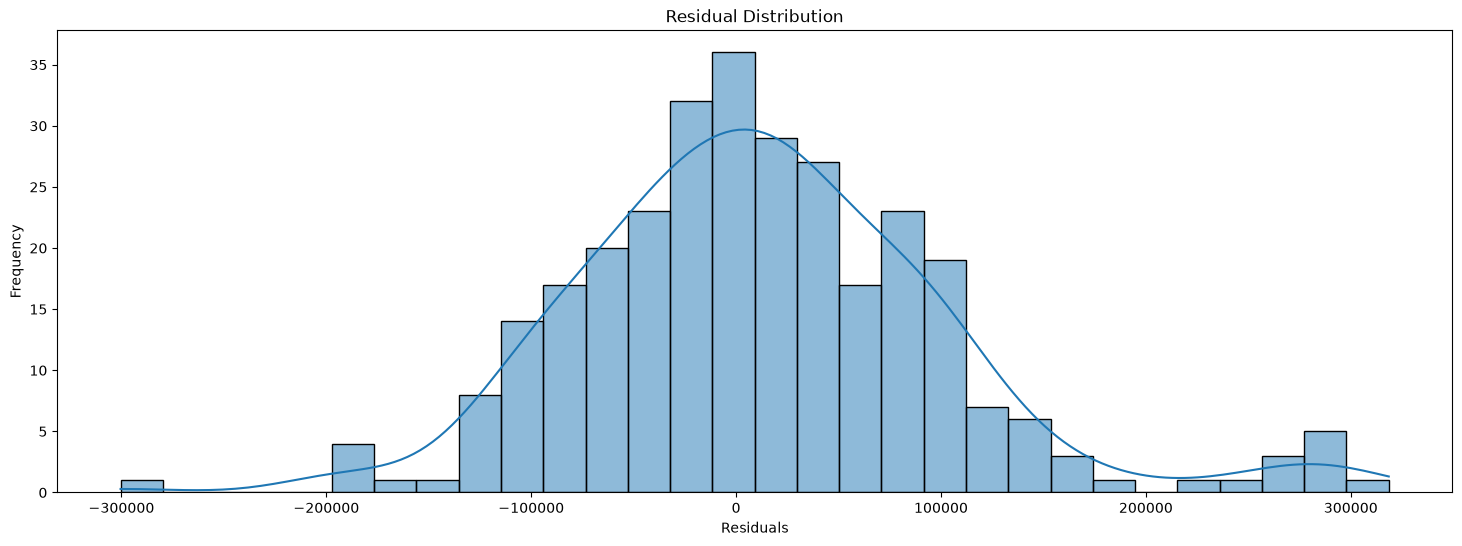

In [66]:
plt.figure(figsize=(18,6))
sns.histplot(residuals, kde=True, bins=30)
plt.title("Residual Distribution")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

***Insights***:

The residuals (difference between actual and predicted prices) form a normal distribution:
This indicates that the model's errors are evenly distributed, without significant bias (e.g., overestimating or underestimating prices consistently).

### Feature Importance

In [ ]:
feature_importance =  pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

In [68]:
feature_importance

,Feature,Coefficient
2,SizeInSqFt,548093.229959
3,Bedrooms,32808.052209
4,Bathrooms,21988.474016
1,PropertyType,21643.415079
5,YearBuilt,21140.170259
6,GarageSpaces,13524.801674
9,MarketTrend,11909.851465
8,NearbySchools,5496.549536
0,Location,-14601.620451
7,LotSize,-401928.685208


In [69]:
feature_importance.sort_values(by='Coefficient', ascending=False)

,Feature,Coefficient
2,SizeInSqFt,548093.229959
3,Bedrooms,32808.052209
4,Bathrooms,21988.474016
1,PropertyType,21643.415079
5,YearBuilt,21140.170259
6,GarageSpaces,13524.801674
9,MarketTrend,11909.851465
8,NearbySchools,5496.549536
0,Location,-14601.620451
7,LotSize,-401928.685208


###  Summary of overal Insights
- Larger properties (SizeInSqFt) have the highest positive impact on house prices.
- The number of bedrooms(Bedrooms) and bathrooms(Bathrooms) significantly increase prices.
- High-rated schools (NearbySchools) are a key driver of pricing in family-friendly neighborhoods.